In [5]:
pip install pandas numpy scikit-learn matplotlib seaborn streamlit joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 67.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 73.6 MB/s eta 0:00:00


In [6]:
# ============================================
# STEP 1–5: LOAD + INSPECT + CLEAN DATA
# ============================================

import pandas as pd
import numpy as np

# 1. Load dataset
df = pd.read_csv("Zomato Dataset.csv")

# 2. Clean column names
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
)

# 3. Display column names
print("Column Names:")
print(df.columns.tolist())

# 4. Remove duplicate rows
df = df.drop_duplicates()

print("\nDuplicate rows removed.")
print("Dataset shape:", df.shape)

# 5. Remove unnecessary ID columns
df = df.drop(
    columns=["ID", "Delivery_person_ID"],
    errors="ignore"
)

# 6. Find the Time_taken column automatically
time_column = None

for col in df.columns:
    if "Time_taken" in col:
        time_column = col
        break

if time_column is None:
    print("\nERROR: Time_taken column not found!")
else:
    print("\nTarget column found:", time_column)

# 7. Numerical columns
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries"
]

# Add target column automatically
if time_column is not None:
    numeric_columns.append(time_column)

# 8. Convert numerical columns
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# 9. Fill numerical missing values
for col in numeric_columns:
    if col in df.columns:
        df[col] = df[col].fillna(df[col].median())

# 10. Fill categorical missing values
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# 11. Final information
print("\n================================")
print("DATASET AFTER CLEANING")
print("================================")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
print(df.head())

Column Names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken_(min)']

Duplicate rows removed.
Dataset shape: (45584, 20)

Target column found: Time_taken_(min)

DATASET AFTER CLEANING
Rows: 45584
Columns: 18

Missing values:
Delivery_person_Age            0
Delivery_person_Ratings        0
Restaurant_latitude            0
Restaurant_longitude           0
Delivery_location_latitude     0
Delivery_location_longitude    0
Order_Date                     0
Time_Orderd                    0
Time_Order_picked              0
Weather_conditions             0
Road_traffic_density           0
Vehicle_condition              0
Type_of_order                  

In [7]:
# ============================================
# STEP 6: CALCULATE DELIVERY DISTANCE
# ============================================

from math import radians, sin, cos, sqrt, atan2

def calculate_distance(lat1, lon1, lat2, lon2):
    """
    Calculate distance between two geographical
    coordinates using the Haversine formula.
    """

    R = 6371  # Earth radius in kilometers

    lat1 = radians(lat1)
    lon1 = radians(lon1)
    lat2 = radians(lat2)
    lon2 = radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        sin(dlat / 2) ** 2
        + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    )

    c = 2 * atan2(sqrt(a), sqrt(1 - a))

    return R * c


# Create distance column
df["distance_km"] = df.apply(
    lambda row: calculate_distance(
        row["Restaurant_latitude"],
        row["Restaurant_longitude"],
        row["Delivery_location_latitude"],
        row["Delivery_location_longitude"]
    ),
    axis=1
)

# Display result
print("Distance calculated successfully!")

print("\nFirst 10 distances:")
print(df["distance_km"].head(10))

print("\nDistance statistics:")
print(df["distance_km"].describe())

Distance calculated successfully!

First 10 distances:
0    10.280582
1     6.242319
2    13.787860
3     2.930258
4    19.396618
5    13.763977
6     6.218001
7    16.849940
8    10.757109
9     4.540574
Name: distance_km, dtype: float64

Distance statistics:
count    45584.000000
mean        99.321320
std       1099.839139
min          1.465067
25%          4.663493
50%          9.264356
75%         13.763977
max      19692.674606
Name: distance_km, dtype: float64


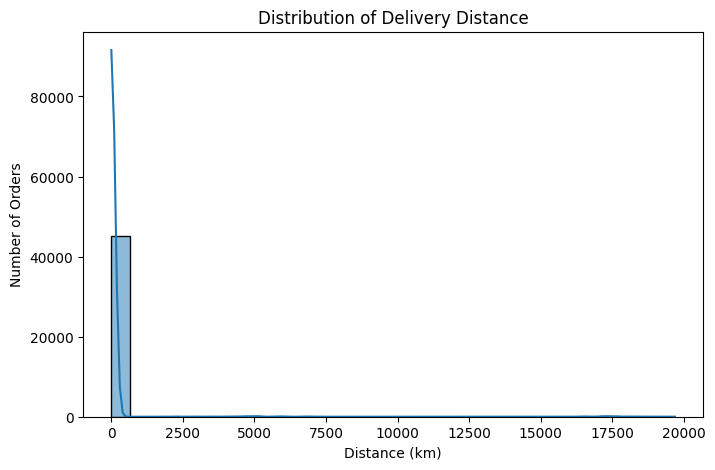

In [8]:
#Step 7 — Check the distance visually
#This tells us how far restaurants are from customers
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    df["distance_km"],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Distance")
plt.xlabel("Distance (km)")
plt.ylabel("Number of Orders")

plt.show()

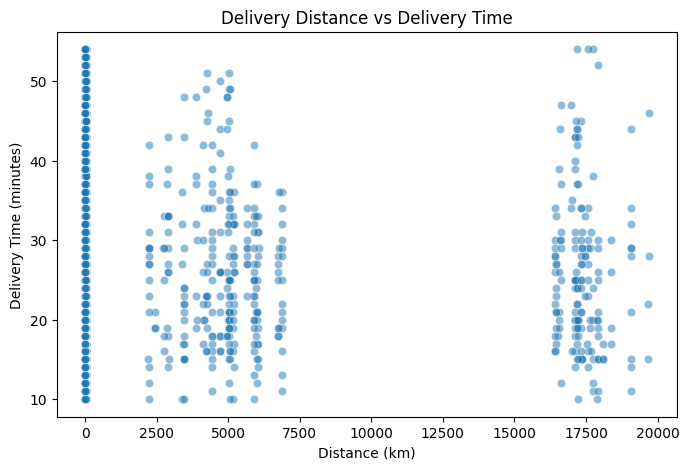

In [9]:
#Then check distance vs delivery time
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="distance_km",
    y=time_column,
    data=df,
    alpha=0.5
)

plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.show()

In [10]:
#STEP 8 — Create Time Features
# ============================================
# STEP 8: TIME FEATURE ENGINEERING
# ============================================

# First check the actual column names
print("Time column:")
print(df["Time_Orderd"].head())

print("\nDate column:")
print(df["Order_Date"].head())


# --------------------------------------------
# 1. Convert Order Date
# --------------------------------------------

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)


# --------------------------------------------
# 2. Convert Time Ordered
# --------------------------------------------

# Convert time to datetime
df["order_time"] = pd.to_datetime(
    df["Time_Orderd"],
    format="%H:%M",
    errors="coerce"
)


# --------------------------------------------
# 3. Extract hour
# --------------------------------------------

df["order_hour"] = df["order_time"].dt.hour


# --------------------------------------------
# 4. Create peak-hour feature
# --------------------------------------------

def check_peak_hour(hour):

    if pd.isna(hour):
        return 0

    # Morning: 7 AM - 9 AM
    # Afternoon: 12 PM - 2 PM
    # Evening: 7 PM - 10 PM

    if (7 <= hour <= 9) or (12 <= hour <= 14) or (19 <= hour <= 22):
        return 1

    return 0


df["is_peak_hour"] = df["order_hour"].apply(check_peak_hour)


# --------------------------------------------
# 5. Extract day of week
# --------------------------------------------

df["day_of_week"] = df["Order_Date"].dt.dayofweek


# --------------------------------------------
# 6. Create weekend feature
# --------------------------------------------

df["is_weekend"] = df["day_of_week"].apply(
    lambda x: 1 if x >= 5 else 0
)


# --------------------------------------------
# 7. Display the new features
# --------------------------------------------

print("\n========================================")
print("TIME FEATURES CREATED")
print("========================================")

print(
    df[
        [
            "Order_Date",
            "Time_Orderd",
            "order_hour",
            "is_peak_hour",
            "day_of_week",
            "is_weekend"
        ]
    ].head(10)
)


Time column:
0    21:55
1    14:55
2    17:30
3    09:20
4    19:50
Name: Time_Orderd, dtype: object

Date column:
0    12-02-2022
1    13-02-2022
2    04-03-2022
3    13-02-2022
4    14-02-2022
Name: Order_Date, dtype: object

TIME FEATURES CREATED
  Order_Date Time_Orderd  order_hour  is_peak_hour  day_of_week  is_weekend
0 2022-12-02       21:55        21.0             1          4.0           0
1        NaT       14:55        14.0             1          NaN           0
2 2022-04-03       17:30        17.0             0          6.0           1
3        NaT       09:20         9.0             1          NaN           0
4        NaT       19:50        19.0             1          NaN           0
5 2022-02-04       20:25        20.0             1          4.0           0
6 2022-01-03       14:55        14.0             1          0.0           0
7        NaT       20:30        20.0             1          NaN           0
8        NaT       20:40        20.0             1          NaN   

In [11]:
#STEP 8.1 — Check the peak hours
print(df["is_peak_hour"].value_counts())
#0 = Non-peak  1 = Peak

is_peak_hour
1    24148
0    21436
Name: count, dtype: int64


In [12]:
#STEP 8.2 — Check weekend orders
print(df["is_weekend"].value_counts())
#0 = Weekday  1 = Weekend

is_weekend
0    40367
1     5217
Name: count, dtype: int64


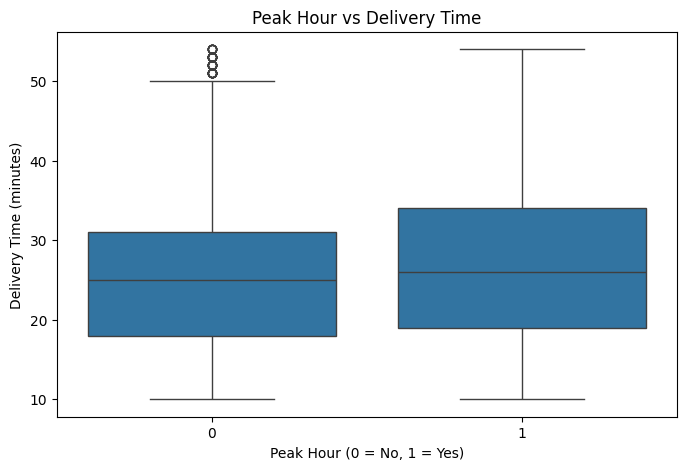

In [13]:
#STEP 8.3 — Visualize delivery time by peak hour
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="is_peak_hour",
    y=time_column,
    data=df
)

plt.title("Peak Hour vs Delivery Time")
plt.xlabel("Peak Hour (0 = No, 1 = Yes)")
plt.ylabel("Delivery Time (minutes)")

plt.show()
#The graph compares delivery times during peak and non-peak hours to determine whether busy ordering periods affect delivery time."

In [14]:
#STEP 8.4 — Check your complete dataset
print(df.shape)

print("\nNew columns:")
print(df.columns.tolist())

(45584, 24)

New columns:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken_(min)', 'distance_km', 'order_time', 'order_hour', 'is_peak_hour', 'day_of_week', 'is_weekend']


In [15]:
#Step 9 — Exploratory Data Analysis
#EDA helps us answer questions like:
##What is the typical delivery time?
##Does high traffic increase delivery time?
#Does bad weather affect delivery time?
#Does longer distance mean longer delivery time?
#Are peak-hour orders slower?
#Which numerical variables are related to delivery time?

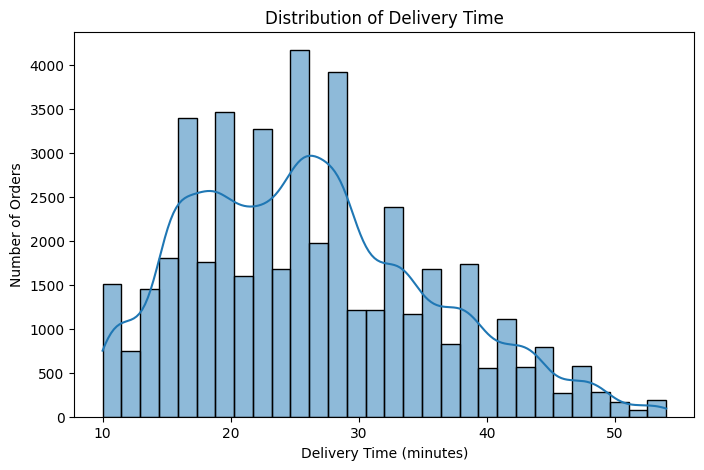

In [16]:
#9.1 — Delivery Time Distribution
#We want to know whether most deliveries take 20 minutes, 30 minutes, 40 minutes, etc.
# ============================================
# EDA 1: DELIVERY TIME DISTRIBUTION
# ============================================

plt.figure(figsize=(8, 5))

sns.histplot(
    df[time_column],
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")

plt.show()
#It groups delivery times into ranges.
#I used a histogram to study the distribution of the target variable, delivery time. It helps identify the most common delivery-time range and whether the distribution contains extreme values

Road_traffic_density
Low       16077
Jam       14139
Medium    10945
High       4423
Name: count, dtype: int64


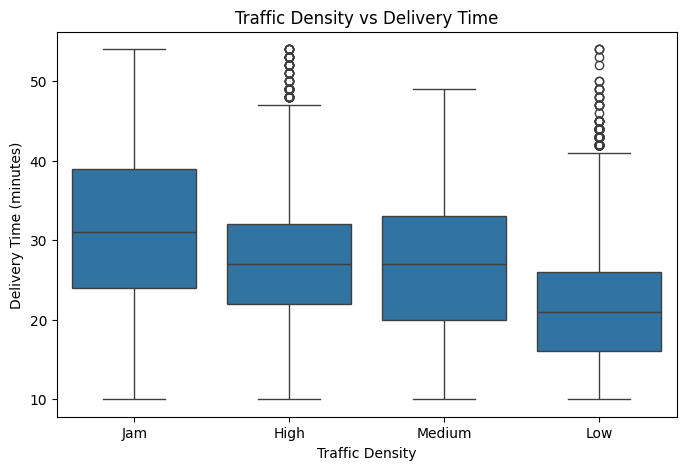

In [17]:
#9.2 — Traffic Density vs Delivery Time ⭐
# First check the categories
print(df["Road_traffic_density"].value_counts())
# You'll see the traffic categories actually present in your dataset.
# ============================================
# EDA 2: TRAFFIC VS DELIVERY TIME
# ============================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Road_traffic_density",
    y=time_column,
    data=df
)

plt.title("Traffic Density vs Delivery Time")
plt.xlabel("Traffic Density")
plt.ylabel("Delivery Time (minutes)")

plt.show()

In [18]:
# compared traffic density with delivery time using a boxplot to examine whether delivery-time distributions differ across traffic conditions."
# "The dataset shows that higher traffic is associated with longer delivery times."

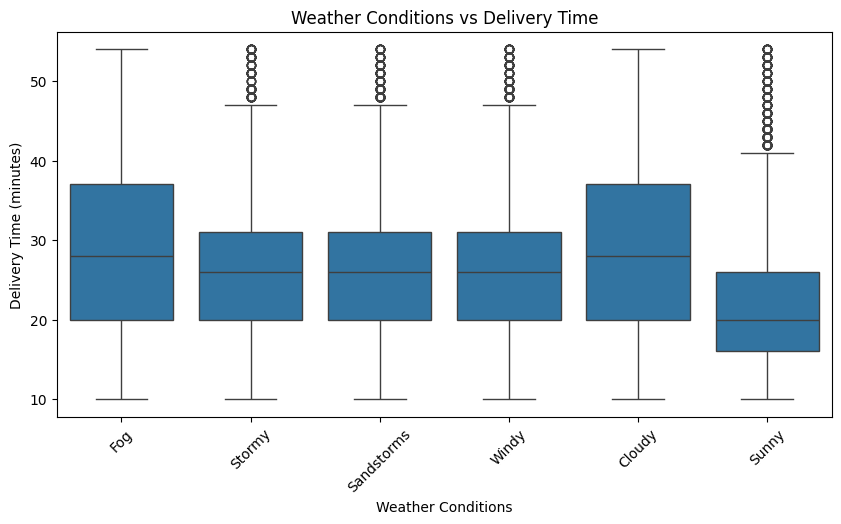

In [19]:
# 9.3 — Weather vs Delivery Time ⭐
# Does delivery time differ under different weather conditions?
# ============================================
# EDA 3: WEATHER VS DELIVERY TIME
# ============================================

plt.figure(figsize=(10, 5))

sns.boxplot(
    x="Weather_conditions",
    y=time_column,
    data=df
)

plt.title("Weather Conditions vs Delivery Time")
plt.xlabel("Weather Conditions")
plt.ylabel("Delivery Time (minutes)")

plt.xticks(rotation=45)

plt.show()

In [20]:
# "I compared delivery-time distributions across weather conditions to determine whether weather is associated with differences in delivery time."

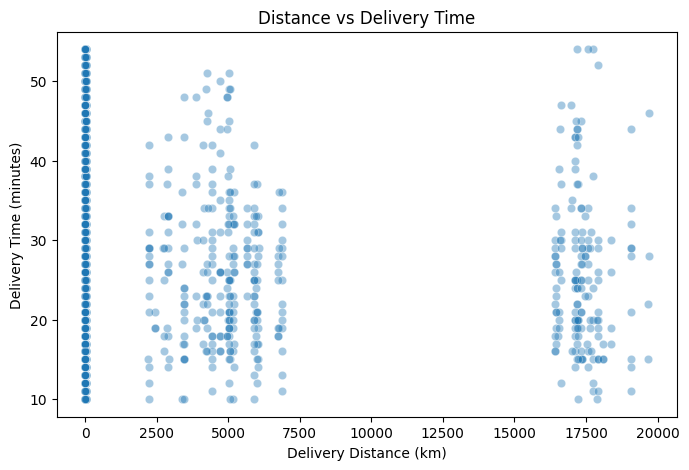

In [21]:
# 9.4 — Distance vs Delivery Time ⭐⭐⭐
# This is especially important because we created distance_km ourselves during feature engineering.
# ============================================
# EDA 4: DISTANCE VS DELIVERY TIME
# ============================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x="distance_km",
    y=time_column,
    data=df,
    alpha=0.4
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Delivery Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.show()

In [22]:
# Restaurant and delivery coordinates were converted into delivery distance using the Haversine formula. I then used a scatterplot to examine the relationship between distance and delivery time."

# If your graph shows an upward pattern:
# "Longer delivery distances generally correspond to longer delivery times."

In [23]:
print(df["distance_km"].describe())

count    45584.000000
mean        99.321320
std       1099.839139
min          1.465067
25%          4.663493
50%          9.264356
75%         13.763977
max      19692.674606
Name: distance_km, dtype: float64


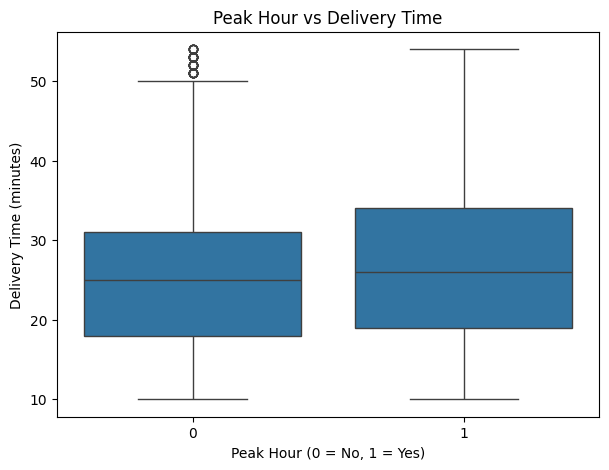

In [24]:
# 9.5 — Peak Hour vs Delivery Time
# ============================================
# EDA 5: PEAK HOUR VS DELIVERY TIME
# ============================================

plt.figure(figsize=(7, 5))

sns.boxplot(
    x="is_peak_hour",
    y=time_column,
    data=df
)

plt.title("Peak Hour vs Delivery Time")
plt.xlabel("Peak Hour (0 = No, 1 = Yes)")
plt.ylabel("Delivery Time (minutes)")

plt.show()
# I engineered a binary peak-hour feature from the order time and compared delivery times between peak and non-peak periods

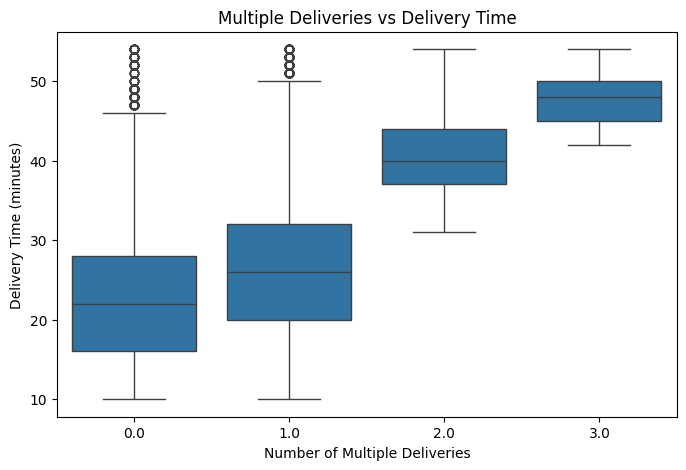

In [25]:
# 9.6 — Multiple Deliveries vs Delivery Time
# This is potentially useful because a delivery partner handling multiple deliveries may have different delivery times.
# ============================================
# EDA 7: MULTIPLE DELIVERIES VS DELIVERY TIME
# ============================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    x="multiple_deliveries",
    y=time_column,
    data=df
)

plt.title("Multiple Deliveries vs Delivery Time")
plt.xlabel("Number of Multiple Deliveries")
plt.ylabel("Delivery Time (minutes)")

plt.show()
# "I analyzed the number of simultaneous/multiple deliveries to determine whether delivery time varies with the rider's delivery workload.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --------------------------------------------
# 1. Select features
# --------------------------------------------

features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "distance_km",
    "Vehicle_condition",
    "multiple_deliveries",
    "order_hour",
    "is_peak_hour",
    "is_weekend",
    "Weather_conditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

# Input features
X = df[features]

# Target
y = df[time_column]


# --------------------------------------------
# 2. Split features into numerical and categorical
# --------------------------------------------

numeric_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "distance_km",
    "Vehicle_condition",
    "multiple_deliveries",
    "order_hour",
    "is_peak_hour",
    "is_weekend"
]

categorical_features = [
    "Weather_conditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]


# --------------------------------------------
# 3. Create preprocessing pipeline
# --------------------------------------------

# Numeric pipeline: Impute NaNs using median, then scale
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline: Impute NaNs with mode, then encode
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


# --------------------------------------------
# 4. Train-test split
# --------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)


# --------------------------------------------
# 5. Display information
# --------------------------------------------

print("========================================")
print("MACHINE LEARNING DATA PREPARATION")
print("========================================")

print("\nInput features:", X.shape)
print("Target:", y.shape)

print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nNumerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nData preparation completed successfully with Imputation!")

MACHINE LEARNING DATA PREPARATION

Input features: (45584, 14)
Target: (45584,)

Training features: (36467, 14)
Testing features: (9117, 14)

Training target: (36467,)
Testing target: (9117,)

Numerical features:
['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km', 'Vehicle_condition', 'multiple_deliveries', 'order_hour', 'is_peak_hour', 'is_weekend']

Categorical features:
['Weather_conditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']

Data preparation completed successfully with Imputation!


In [27]:
# ============================================
# STEP 11: TRAIN AND COMPARE ML MODELS
# ============================================

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================
# 1. LINEAR REGRESSION
# ============================================

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        linear_pred
    )
)

linear_r2 = r2_score(
    y_test,
    linear_pred
)


# ============================================
# 2. DECISION TREE
# ============================================

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=15,
                random_state=42
            )
        )
    ]
)

tree_model.fit(X_train, y_train)

tree_pred = tree_model.predict(X_test)

tree_mae = mean_absolute_error(
    y_test,
    tree_pred
)

tree_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        tree_pred
    )
)

tree_r2 = r2_score(
    y_test,
    tree_pred
)


# ============================================
# 3. RANDOM FOREST
# ============================================

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_pred
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        rf_pred
    )
)

rf_r2 = r2_score(
    y_test,
    rf_pred
)


# ============================================
# 4. MODEL COMPARISON
# ============================================

results = pd.DataFrame({

    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],

    "MAE": [
        linear_mae,
        tree_mae,
        rf_mae
    ],

    "RMSE": [
        linear_rmse,
        tree_rmse,
        rf_rmse
    ],

    "R2": [
        linear_r2,
        tree_r2,
        rf_r2
    ]
})


print("\n========================================")
print("MODEL PERFORMANCE")
print("========================================")

print(results.round(3))


# ============================================
# 5. BEST MODEL
# ============================================

best_model = results.loc[
    results["MAE"].idxmin(),
    "Model"
]

print("\nBest model based on MAE:", best_model)


MODEL PERFORMANCE
               Model    MAE   RMSE     R2
0  Linear Regression  4.960  6.259  0.556
1      Decision Tree  3.503  4.556  0.765
2      Random Forest  3.193  4.047  0.814

Best model based on MAE: Random Forest


First 10 predictions:
   Actual_Time  Predicted_Time  Error  Absolute_Error
0           33           32.76   0.24            0.24
1           28           25.56   2.44            2.44
2           22           20.48   1.52            1.52
3           25           22.43   2.57            2.57
4           35           40.45  -5.45            5.45
5           27           27.77  -0.77            0.77
6           48           46.85   1.15            1.15
7           27           28.54  -1.54            1.54
8           24           20.60   3.40            3.40
9           18           23.39  -5.39            5.39


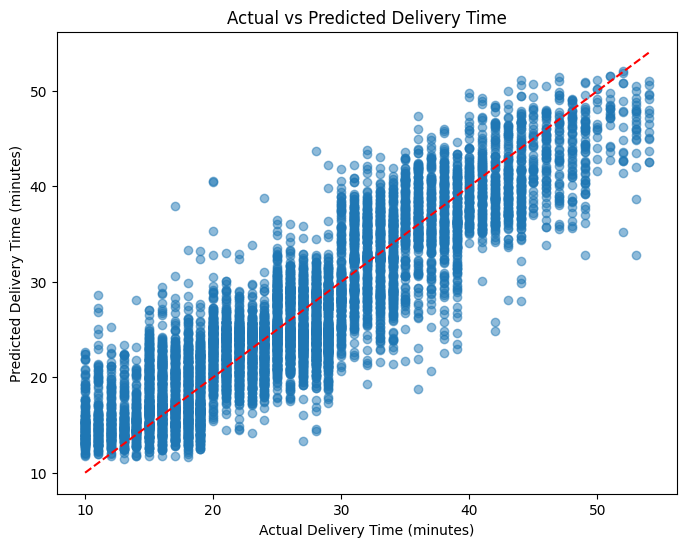


Average Absolute Error: 3.19 minutes

Worst Predictions:
      Actual_Time  Predicted_Time  Error  Absolute_Error
4038           17           37.95 -20.95           20.95
4634           20           40.58 -20.58           20.58
2069           20           40.50 -20.50           20.50
7139           53           32.81  20.19           20.19
4721           11           28.59 -17.59           17.59
3663           36           18.74  17.26           17.26
1198           42           24.84  17.16           17.16
4565           52           35.23  16.77           16.77
1629           37           20.68  16.32           16.32
8715           11           27.23 -16.23           16.23


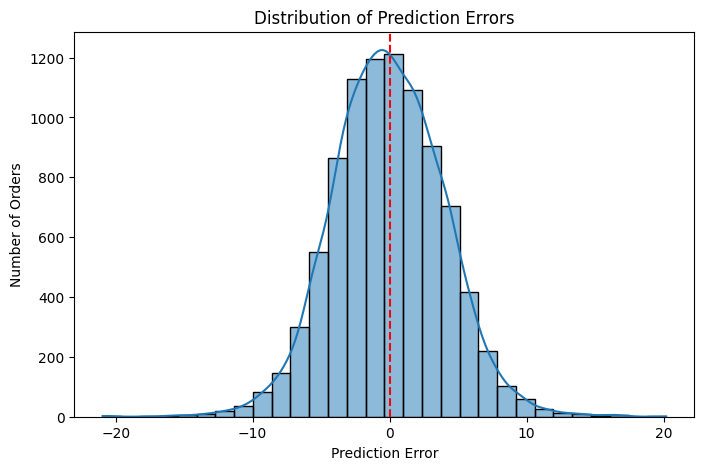


NEW ORDER PREDICTION
Estimated Delivery Time: 21.4 minutes


In [28]:
# ============================================
# STEP 12: PREDICTION ANALYSIS
# ============================================

# --------------------------------------------
# 1. Create prediction results
# --------------------------------------------

prediction_results = pd.DataFrame({
    "Actual_Time": y_test.values,
    "Predicted_Time": rf_pred
})

prediction_results["Error"] = (
    prediction_results["Actual_Time"]
    - prediction_results["Predicted_Time"]
)

prediction_results["Absolute_Error"] = (
    prediction_results["Error"].abs()
)

print("First 10 predictions:")
print(
    prediction_results.head(10).round(2)
)


# --------------------------------------------
# 2. Actual vs Predicted graph
# --------------------------------------------

plt.figure(figsize=(8, 6))

plt.scatter(
    prediction_results["Actual_Time"],
    prediction_results["Predicted_Time"],
    alpha=0.5
)

min_value = min(
    prediction_results["Actual_Time"].min(),
    prediction_results["Predicted_Time"].min()
)

max_value = max(
    prediction_results["Actual_Time"].max(),
    prediction_results["Predicted_Time"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Time")

plt.show()


# --------------------------------------------
# 3. Average error
# --------------------------------------------

average_error = prediction_results[
    "Absolute_Error"
].mean()

print(
    "\nAverage Absolute Error:",
    round(average_error, 2),
    "minutes"
)


# --------------------------------------------
# 4. Worst predictions
# --------------------------------------------

worst_predictions = prediction_results.sort_values(
    by="Absolute_Error",
    ascending=False
)

print("\nWorst Predictions:")
print(
    worst_predictions.head(10).round(2)
)


# --------------------------------------------
# 5. Error distribution
# --------------------------------------------

plt.figure(figsize=(8, 5))

sns.histplot(
    prediction_results["Error"],
    bins=30,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error")
plt.ylabel("Number of Orders")

plt.show()


# --------------------------------------------
# 6. New order prediction
# --------------------------------------------

# Define default test variables to resolve the NameError
age = 28
rating = 4.7
distance = 5.2
vehicle_condition = 2
multiple_deliveries = 1
order_hour = 20
is_peak_hour = 1
is_weekend = 0
weather = "Rainy"
traffic = "High"
order_type = "Meal"
vehicle_type = "motorcycle"
festival = "No"
city = "Metropolitian"

new_order = pd.DataFrame({
    "Delivery_person_Age": [age],
    "Delivery_person_Ratings": [rating],
    "distance_km": [distance],
    "Vehicle_condition": [vehicle_condition],
    "multiple_deliveries": [multiple_deliveries],
    "order_hour": [order_hour],
    "is_peak_hour": [is_peak_hour],
    "is_weekend": [is_weekend],
    "Weather_conditions": [weather],
    "Road_traffic_density": [traffic],
    "Type_of_order": [order_type],
    "Type_of_vehicle": [vehicle_type],
    "Festival": [festival],
    "City": [city]
})

predicted_time = rf_model.predict(new_order)

print("\n================================")
print("NEW ORDER PREDICTION")
print("===============================")

print(
    "Estimated Delivery Time:",
    round(predicted_time[0], 1),
    "minutes"
)

DELAY SUMMARY
Total test orders: 9117
Delayed orders: 4421
Delay percentage: 48.49 %


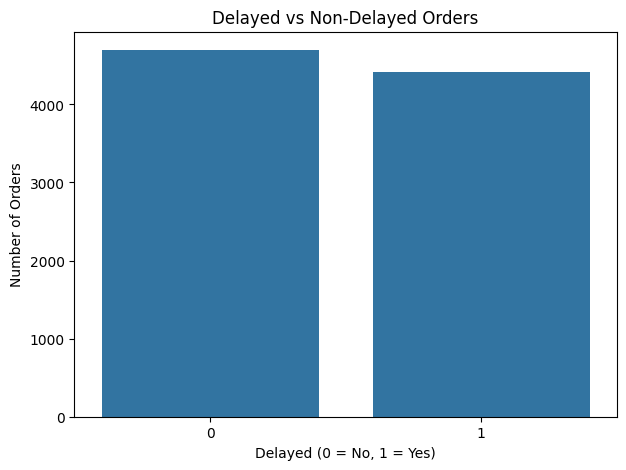


Delay Percentage by Traffic:
Road_traffic_density
High      45.18
Jam       48.64
Low       49.89
Medium    47.62
Name: Delayed, dtype: float64


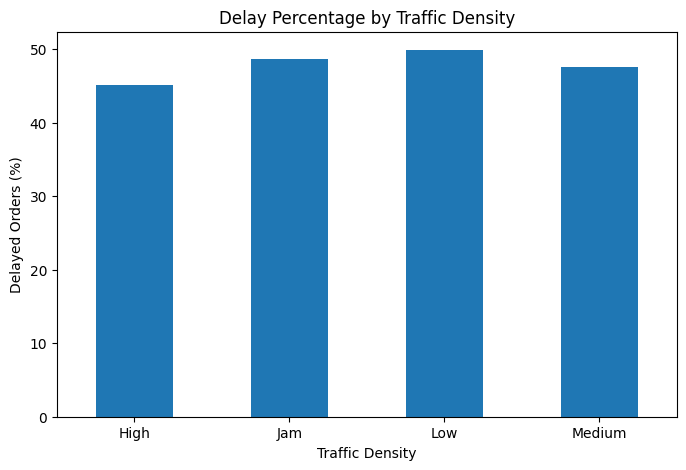


Delay Percentage by Weather:
Weather_conditions
Cloudy        48.95
Fog           49.18
Sandstorms    49.15
Stormy        47.84
Sunny         46.84
Windy         48.87
Name: Delayed, dtype: float64


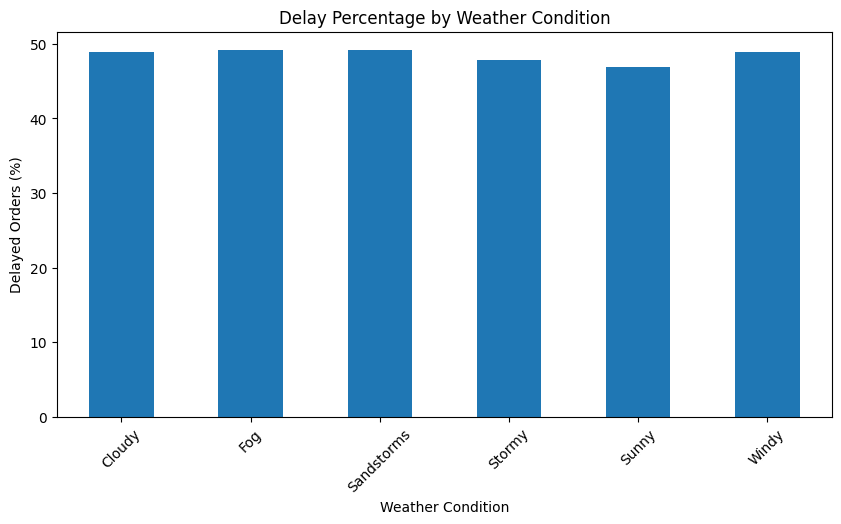


Delay Percentage by Distance:
Distance_Group
0-2 km     46.12
2-5 km     48.71
5-10 km    48.57
10+ km     48.82
Name: Delayed, dtype: float64


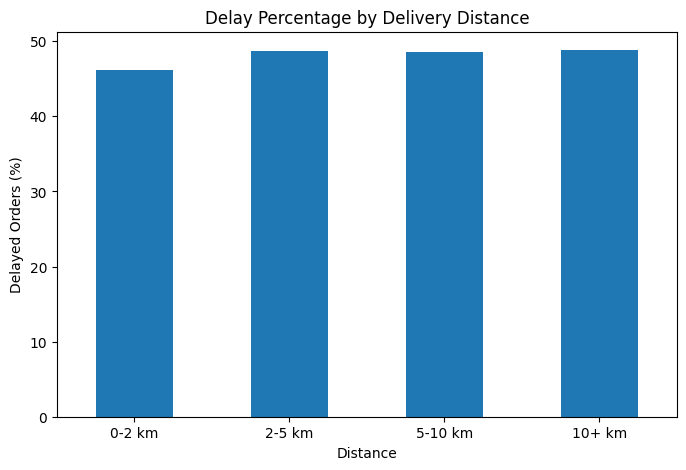


Delay Percentage by Peak Hour:
is_peak_hour
0    48.63
1    48.37
Name: Delayed, dtype: float64


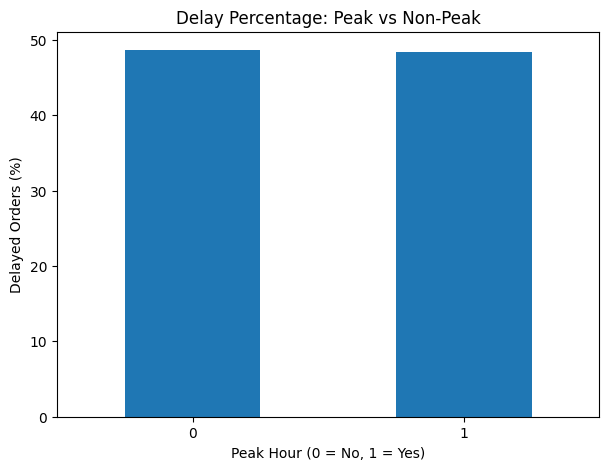


BIGGEST DELAYS
       Actual_Time  Predicted_Time  Delay_Minutes  distance_km  \
30884           53           32.81          20.19         6.12   
32136           36           18.74          17.26         3.10   
44936           42           24.84          17.16        17.10   
9545            52           35.23          16.77        10.64   
4884            37           20.68          16.32         6.15   
35155           42           25.80          16.20         6.23   
23269           49           32.81          16.19         6.08   
5746            39           22.91          16.09      5071.96   
33582           44           27.99          16.01        12.26   
39690           39           23.52          15.48         4.72   

      Road_traffic_density Weather_conditions  is_peak_hour  
30884                 High              Sunny             1  
32136                  Low                Fog             1  
44936                  Low                Fog             1  
9545     

In [29]:
# ============================================
# STEP 13: DELAY ANALYSIS
# ============================================

# --------------------------------------------
# 1. Match test rows with predictions
# --------------------------------------------

delay_df = df.loc[y_test.index].copy()

delay_df["Actual_Time"] = y_test
delay_df["Predicted_Time"] = rf_pred

# Delay relative to model prediction
delay_df["Delay_Minutes"] = (
    delay_df["Actual_Time"]
    - delay_df["Predicted_Time"]
)


# --------------------------------------------
# 2. Classify delayed orders
# --------------------------------------------

delay_df["Delayed"] = (
    delay_df["Delay_Minutes"] > 0
).astype(int)


# --------------------------------------------
# 3. Delay percentage
# --------------------------------------------

total_orders = len(delay_df)

delayed_orders = (
    delay_df["Delayed"] == 1
).sum()

delay_percentage = (
    delayed_orders / total_orders
) * 100

print("========================================")
print("DELAY SUMMARY")
print("========================================")

print("Total test orders:", total_orders)
print("Delayed orders:", delayed_orders)
print(
    "Delay percentage:",
    round(delay_percentage, 2),
    "%"
)


# --------------------------------------------
# 4. Delayed vs non-delayed graph
# --------------------------------------------

plt.figure(figsize=(7, 5))

sns.countplot(
    x="Delayed",
    data=delay_df
)

plt.title("Delayed vs Non-Delayed Orders")
plt.xlabel("Delayed (0 = No, 1 = Yes)")
plt.ylabel("Number of Orders")

plt.show()


# --------------------------------------------
# 5. Traffic vs delay
# --------------------------------------------

traffic_delay = (
    delay_df
    .groupby("Road_traffic_density")["Delayed"]
    .mean()
    * 100
)

print("\nDelay Percentage by Traffic:")
print(traffic_delay.round(2))

plt.figure(figsize=(8, 5))

traffic_delay.plot(kind="bar")

plt.title("Delay Percentage by Traffic Density")
plt.xlabel("Traffic Density")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=0)

plt.show()


# --------------------------------------------
# 6. Weather vs delay
# --------------------------------------------

weather_delay = (
    delay_df
    .groupby("Weather_conditions")["Delayed"]
    .mean()
    * 100
)

print("\nDelay Percentage by Weather:")
print(weather_delay.round(2))

plt.figure(figsize=(10, 5))

weather_delay.plot(kind="bar")

plt.title("Delay Percentage by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=45)

plt.show()


# --------------------------------------------
# 7. Distance vs delay
# --------------------------------------------

delay_df["Distance_Group"] = pd.cut(
    delay_df["distance_km"],
    bins=[0, 2, 5, 10, np.inf],
    labels=[
        "0-2 km",
        "2-5 km",
        "5-10 km",
        "10+ km"
    ]
)

distance_delay = (
    delay_df
    .groupby(
        "Distance_Group",
        observed=False
    )["Delayed"]
    .mean()
    * 100
)

print("\nDelay Percentage by Distance:")
print(distance_delay.round(2))

plt.figure(figsize=(8, 5))

distance_delay.plot(kind="bar")

plt.title("Delay Percentage by Delivery Distance")
plt.xlabel("Distance")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=0)

plt.show()


# --------------------------------------------
# 8. Peak hour vs delay
# --------------------------------------------

peak_delay = (
    delay_df
    .groupby("is_peak_hour")["Delayed"]
    .mean()
    * 100
)

print("\nDelay Percentage by Peak Hour:")
print(peak_delay.round(2))

plt.figure(figsize=(7, 5))

peak_delay.plot(kind="bar")

plt.title("Delay Percentage: Peak vs Non-Peak")
plt.xlabel("Peak Hour (0 = No, 1 = Yes)")
plt.ylabel("Delayed Orders (%)")

plt.xticks(rotation=0)

plt.show()


# --------------------------------------------
# 9. Biggest delays
# --------------------------------------------

biggest_delays = delay_df.sort_values(
    by="Delay_Minutes",
    ascending=False
)

print("\n========================================")
print("BIGGEST DELAYS")
print("========================================")

print(
    biggest_delays[
        [
            "Actual_Time",
            "Predicted_Time",
            "Delay_Minutes",
            "distance_km",
            "Road_traffic_density",
            "Weather_conditions",
            "is_peak_hour"
        ]
    ].head(10).round(2)
)

TOP 15 FEATURES
                       Clean_Feature  Importance
1       num__Delivery_person_Ratings      0.2072
2                   num__distance_km      0.1368
4           num__multiple_deliveries      0.1202
16     cat__Road_traffic_density_Low      0.1067
0           num__Delivery_person_Age      0.1013
3             num__Vehicle_condition      0.0727
12     cat__Weather_conditions_Sunny      0.0716
9        cat__Weather_conditions_Fog      0.0467
8     cat__Weather_conditions_Cloudy      0.0436
17  cat__Road_traffic_density_Medium      0.0160
5                    num__order_hour      0.0122
27                 cat__Festival_Yes      0.0058
26                  cat__Festival_No      0.0052
15     cat__Road_traffic_density_Jam      0.0051
18         cat__Type_of_order_Buffet      0.0044


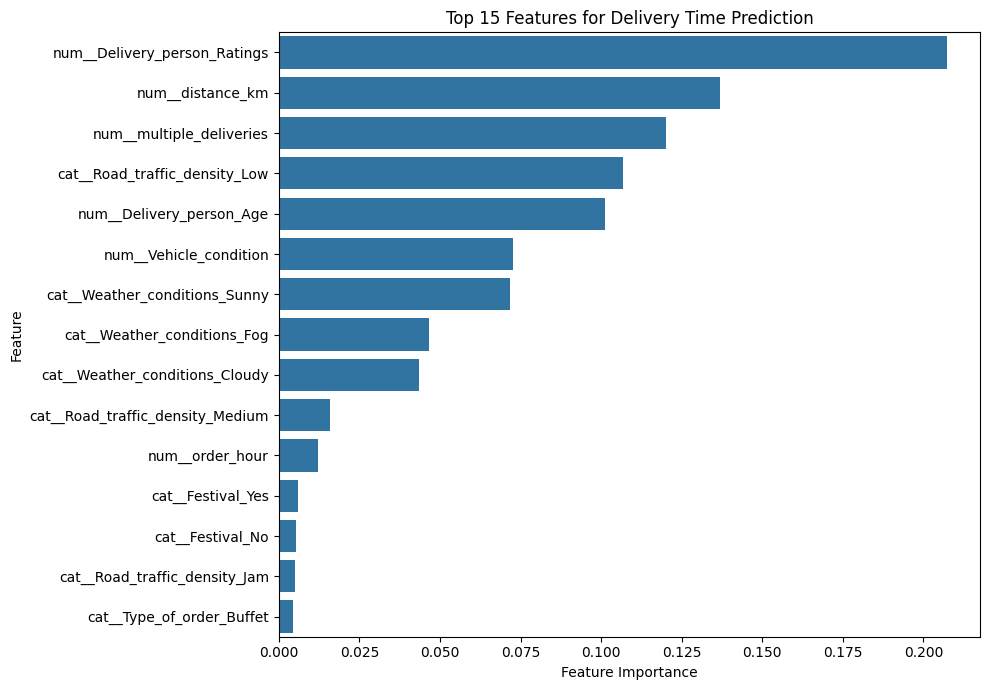


GROUPED FEATURE IMPORTANCE
                                  Feature  Importance
0            num__Delivery_person_Ratings      0.2072
1                        num__distance_km      0.1368
2                num__multiple_deliveries      0.1202
3           cat__Road_traffic_density_Low      0.1067
4                num__Delivery_person_Age      0.1013
5                  num__Vehicle_condition      0.0727
6           cat__Weather_conditions_Sunny      0.0716
7             cat__Weather_conditions_Fog      0.0467
8          cat__Weather_conditions_Cloudy      0.0436
9        cat__Road_traffic_density_Medium      0.0160
10                        num__order_hour      0.0122
11                      cat__Festival_Yes      0.0058
12                       cat__Festival_No      0.0052
13          cat__Road_traffic_density_Jam      0.0051
14              cat__Type_of_order_Buffet      0.0044
15              cat__Type_of_order_Drinks      0.0042
16                cat__Type_of_order_Meal      0.0042


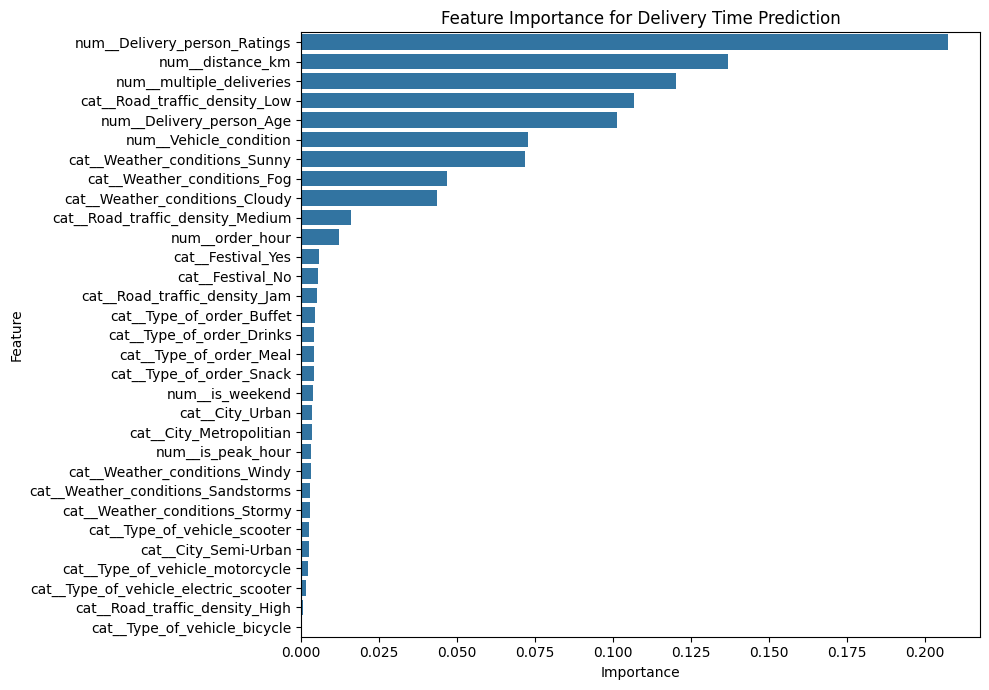

In [30]:
# ============================================
# STEP 14: FEATURE IMPORTANCE ANALYSIS
# ============================================

# --------------------------------------------
# 1. Get Random Forest from pipeline
# --------------------------------------------

rf = rf_model.named_steps["model"]


# --------------------------------------------
# 2. Get transformed feature names
# --------------------------------------------

feature_names = (
    rf_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)


# --------------------------------------------
# 3. Get feature importance
# --------------------------------------------

importance_values = rf.feature_importances_


# --------------------------------------------
# 4. Create importance dataframe
# --------------------------------------------

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})


# --------------------------------------------
# 5. Sort by importance
# --------------------------------------------

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)


# --------------------------------------------
# 6. Clean feature names
# --------------------------------------------

importance_df["Clean_Feature"] = (
    importance_df["Feature"]
    .str.replace(
        "categorical__",
        "",
        regex=False
    )
    .str.replace(
        "remainder__",
        "",
        regex=False
    )
)


# --------------------------------------------
# 7. Show top 15 encoded features
# --------------------------------------------

print("========================================")
print("TOP 15 FEATURES")
print("========================================")

print(
    importance_df[
        [
            "Clean_Feature",
            "Importance"
        ]
    ].head(15).round(4)
)


# --------------------------------------------
# 8. Plot top 15 encoded features
# --------------------------------------------

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Clean_Feature"
)

plt.title(
    "Top 15 Features for Delivery Time Prediction"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.show()


# --------------------------------------------
# 9. Group one-hot features
# --------------------------------------------

grouped_importance = {}

for _, row in importance_df.iterrows():

    feature = row["Clean_Feature"]
    importance = row["Importance"]

    original_feature = feature

    for category in categorical_features:

        if feature.startswith(
            category + "_"
        ):

            original_feature = category
            break

    grouped_importance[
        original_feature
    ] = (
        grouped_importance.get(
            original_feature,
            0
        )
        + importance
    )


# --------------------------------------------
# 10. Create grouped dataframe
# --------------------------------------------

grouped_importance_df = pd.DataFrame(
    list(
        grouped_importance.items()
    ),
    columns=[
        "Feature",
        "Importance"
    ]
)

grouped_importance_df = (
    grouped_importance_df
    .sort_values(
        by="Importance",
        ascending=False
    )
)


# --------------------------------------------
# 11. Print grouped importance
# --------------------------------------------

print("\n========================================")
print("GROUPED FEATURE IMPORTANCE")
print("========================================")

print(
    grouped_importance_df.round(4)
)


# --------------------------------------------
# 12. Plot grouped importance
# --------------------------------------------

plt.figure(figsize=(10, 7))

sns.barplot(
    data=grouped_importance_df,
    x="Importance",
    y="Feature"
)

plt.title(
    "Feature Importance for Delivery Time Prediction"
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()

plt.show()

In [31]:
# ==========================================================
# STEP 15: FINAL FOOD DELIVERY PREDICTION SYSTEM
# ==========================================================

import joblib
import pandas as pd

# ==========================================================
# 1. DELIVERY TIME PREDICTION FUNCTION
# ==========================================================

def predict_delivery_time(
    age,
    rating,
    distance,
    vehicle_condition,
    multiple_deliveries,
    order_hour,
    is_peak_hour,
    is_weekend,
    weather,
    traffic,
    order_type,
    vehicle_type,
    festival,
    city
):
    new_order = pd.DataFrame({
        "Delivery_person_Age": [age],
        "Delivery_person_Ratings": [rating],
        "distance_km": [distance],
        "Vehicle_condition": [vehicle_condition],
        "multiple_deliveries": [multiple_deliveries],
        "order_hour": [order_hour],
        "is_peak_hour": [is_peak_hour],
        "is_weekend": [is_weekend],
        "Weather_conditions": [weather],
        "Road_traffic_density": [traffic],
        "Type_of_order": [order_type],
        "Type_of_vehicle": [vehicle_type],
        "Festival": [festival],
        "City": [city]
    })
    prediction = rf_model.predict(new_order)
    return prediction[0]

# ==========================================================
# 2. DELAY RISK FUNCTION
# ==========================================================

def calculate_delay_risk(
    distance,
    multiple_deliveries,
    is_peak_hour,
    weather,
    traffic
):
    risk_score = 0
    # Distance
    if distance > 10:
        risk_score += 2
    elif distance > 5:
        risk_score += 1

    # Multiple deliveries
    if multiple_deliveries >= 2:
        risk_score += 2
    elif multiple_deliveries == 1:
        risk_score += 1

    # Peak hour
    if is_peak_hour == 1:
        risk_score += 1

    # Traffic
    if traffic in ["High", "Jam"]:
        risk_score += 2
    elif traffic == "Medium":
        risk_score += 1

    # Weather
    if weather in ["Rainy", "Stormy", "Foggy"]:
        risk_score += 2

    # Risk classification
    if risk_score >= 6:
        risk = "HIGH"
    elif risk_score >= 3:
        risk = "MEDIUM"
    else:
        risk = "LOW"
    return risk

# ==========================================================
# 3. COMPLETE FOOD DELIVERY SYSTEM
# ==========================================================

def food_delivery_prediction(
    age,
    rating,
    distance,
    vehicle_condition,
    multiple_deliveries,
    order_hour,
    is_peak_hour,
    is_weekend,
    weather,
    traffic,
    order_type,
    vehicle_type,
    festival,
    city
):
    # Predict delivery time
    predicted_time = predict_delivery_time(
        age,
        rating,
        distance,
        vehicle_condition,
        multiple_deliveries,
        order_hour,
        is_peak_hour,
        is_weekend,
        weather,
        traffic,
        order_type,
        vehicle_type,
        festival,
        city
    )

    # Calculate delay risk
    risk = calculate_delay_risk(
        distance,
        multiple_deliveries,
        is_peak_hour,
        weather,
        traffic
    )

    # Display result
    print("\n")
    print("==============================================")
    print("       FOOD DELIVERY PREDICTION SYSTEM")
    print("==============================================")
    print("\nEstimated Delivery Time:", round(predicted_time, 1), "minutes")
    print("Delay Risk:", risk)
    print("\n==============================================")
    return predicted_time, risk

# ==========================================================
# 4. TEST THE FINAL SYSTEM
# ==========================================================

predicted_time, risk = food_delivery_prediction(
    age=28,
    rating=4.7,
    distance=5.2,
    vehicle_condition=2,
    multiple_deliveries=1,
    order_hour=20,
    is_peak_hour=1,
    is_weekend=0,
    weather="Rainy",
    traffic="High",
    order_type="Meal",
    vehicle_type="motorcycle",
    festival="No",
    city="Metropolitian"
)

# ==========================================================
# 5. SAVE MODEL AND INFORMATION
# ==========================================================

joblib.dump(rf_model, "food_delivery_random_forest.pkl")
print("\nRandom Forest model saved as: food_delivery_random_forest.pkl")

model_information = {
    "features": features,
    "categorical_features": categorical_features
}
joblib.dump(model_information, "model_information.pkl")
print("Model information saved successfully!")

# ==========================================================
# 6. FINAL MODEL REPORT
# ==========================================================

print("\n")
print("==============================================")
print("          FINAL MODEL PERFORMANCE")
print("==============================================")
print("\nBest Model:", best_model)
print("\nAll Model Results:")
print(results.round(3))
print("\nRandom Forest metrics:")
print("  MAE :", round(rf_mae, 3), "minutes")
print("  RMSE:", round(rf_rmse, 3), "minutes")
print("  R²  :", round(rf_r2, 3))
print("\n==============================================")
print("             PROJECT COMPLETE")
print("==============================================")



       FOOD DELIVERY PREDICTION SYSTEM

Estimated Delivery Time: 21.4 minutes
Delay Risk: HIGH


Random Forest model saved as: food_delivery_random_forest.pkl
Model information saved successfully!


          FINAL MODEL PERFORMANCE

Best Model: Random Forest

All Model Results:
               Model    MAE   RMSE     R2
0  Linear Regression  4.960  6.259  0.556
1      Decision Tree  3.503  4.556  0.765
2      Random Forest  3.193  4.047  0.814

Random Forest metrics:
  MAE : 3.193 minutes
  RMSE: 4.047 minutes
  R²  : 0.814

             PROJECT COMPLETE


After we've applied the transformations, you

For using the dataset in modeling and and algorithm deployment, we'll write a, to_csv pipeline. However, we'll first change a folder structure of output (using os) to make sure they're in local folder `data/` instead of `experiments/` so that we have clean and structured directories.

Since the local directory was modified since the initialization of work on the project, the current directories are as follows:

Our data is in fact, inside a `data/raw/` folder, with `processed/` folder already existing inside `data/`.

So we'll save our pipeline to `data/processed/` directory.

Now we'll read the train, test, and val split, for both tabular, text, and combined dataset.

### 2. Loading the Tabular Datasets

We will now read `_tabular_train.csv`, `_tabular_test.csv`, and `_tabular_val.csv` of each split and apply imputation of the numerical variables using median on the training set first, then we'll save those values to apply on the validation and test datasets. Since we already removed high correlation and low variance features, we do not need to do that here.

Let's first define all variables. Since the variable `time_diff` in train had a negative value (an outlier / error), we'll drop it.

We notice `Order_Date` in train has some missing values (NaT). Since `Order_Date` is not needed for modeling, let's drop it from the dataset entirely.

We also need to make sure we split X & Y correctly. Let's do that for train, test, and val.

Now we will apply imputation and save the medians to apply on the test and validation datasets.

With our columns imputed, the next step is encoding our categorical values. We'll find any categorical columns and apply OneHotEncoder.

Now, we will align the datasets since they may have different columns due to OneHotEncoding.

Wait, we noticed that `Time_taken_(min)` is missing from `X_train_encoded_align`. That's because the Y-variables are separated first. Let's check.

Now we can save the tabular dataset (X & Y).

Let's verify the files have indeed been created.

### 3. Loading the Text Datasets

Similarly, we will now load the text datasets (`_text_train.csv`, `_text_test.csv`, and `_text_val.csv`) and apply the TF-IDF feature extraction on the training set, and then transform the test and validation set using the learned TF-IDF representation.

Let's first handle potential missing values in `combined_text` before fitting TF-IDF.

Now we fit TF-IDF vectorizer on `X_train_text` and transform `X_train_text`, `X_test_text`, and `X_val_text`.

Let's convert our sparse matrices to Pandas DataFrames for consistent saving.

Now we'll save our text dataset (X & Y).

Let's verify the text files have indeed been created.

### 4. Loading the Combined Datasets

Finally, we will concatenate the processed tabular features and TF-IDF features to form our combined datasets. This combined dataset is ideal for hybrid models or advanced deep learning models that leverage both tabular and textual data simultaneously.

Let's concatenate the features along the columns (axis=1) and verify the final shapes.

Let's save our combined datasets (X & Y).

Let's verify the combined files have indeed been created.

Excellent, all files were generated successfully in the `data/processed/` folder!

In [32]:
import joblib

joblib.dump(
    rf_model,
    "food_delivery_random_forest.pkl"
)

joblib.dump(
    {
        "features": features,
        "categorical_features": categorical_features
    },
    "model_information.pkl"
)

results.to_csv(
    "model_results.csv",
    index=False
)

print("Files saved successfully!")

Files saved successfully!


In [33]:
!ls

'archive (2).zip'		   model_information.pkl   sample_data
 food_delivery_random_forest.pkl   model_results.csv	  'Zomato Dataset.csv'


In [34]:
!pip install -q streamlit pyngrok

In [35]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# PAGE CONFIG
# ============================================================

st.set_page_config(
    page_title="Food Delivery Prediction",
    page_icon="🍔",
    layout="wide"
)

# ============================================================
# LOAD MODEL
# ============================================================

@st.cache_resource
def load_model():
    return joblib.load(
        "food_delivery_random_forest.pkl"
    )

rf_model = load_model()

# ============================================================
# LOAD RESULTS
# ============================================================

@st.cache_data
def load_results():
    try:
        return pd.read_csv(
            "model_results.csv"
        )
    except:
        return None

results = load_results()

# ============================================================
# CUSTOM STYLE
# ============================================================

st.markdown(
    """
    <style>
    .title {
        font-size: 40px;
        font-weight: bold;
        color: #ff4b4b;
    }
    </style>
    """,
    unsafe_allow_html=True
)

# ============================================================
# SIDEBAR
# ============================================================

st.sidebar.title("🍔 Food Delivery AI")

page = st.sidebar.radio(
    "Navigation",
    [
        "🏠 Home",
        "🤖 Prediction",
        "📊 Model Performance",
        "📈 Feature Importance",
        "ℹ️ About"
    ]
)

# ============================================================
# HEADER
# ============================================================

st.markdown(
    '<div class="title">🍔 Food Delivery Time Prediction</div>',
    unsafe_allow_html=True
)

st.caption(
    "AI-Based Food Delivery Time Prediction and Delay Analysis System"
)

# ============================================================
# HOME
# ============================================================

if page == "🏠 Home":
    st.header("🏠 Dashboard Overview")
    st.write(
        """
        This system uses Machine Learning to predict food delivery
        time based on delivery distance, traffic, weather,
        delivery workload, vehicle condition and other factors.
        """
    )
    st.divider()

    col1, col2, col3, col4 = st.columns(4)
    with col1:
        st.metric("Model", "Random Forest")
    with col2:
        st.metric("Problem", "Regression")
    with col3:
        st.metric("Prediction", "Minutes")
    with col4:
        st.metric("Analysis", "Delay Risk")

    st.divider()
    st.subheader("🔄 System Workflow")
    st.info(
        "Order Details → Data Processing → Random Forest → "
        "Delivery Time Prediction → Delay Risk"
    )

    st.subheader("📌 Main Features")
    st.markdown(
        """
        - 📍 Distance
        - 🚦 Traffic
        - 🌧️ Weather
        - 🕐 Order hour
        - 🛵 Vehicle condition
        - ⭐ Delivery person rating
        - 📦 Multiple deliveries
        - 🎉 Festival
        - 🏙️ City
        """
    )

# ============================================================
# PREDICTION
# ============================================================

elif page == "🤖 Prediction":
    st.header("🤖 Predict Delivery Time")
    st.write("Enter the details of a new food delivery.")

    # DELIVERY PERSON
    st.subheader("👤 Delivery Person")
    col1, col2 = st.columns(2)
    with col1:
        age = st.number_input("Delivery Person Age", 18, 60, 28)
    with col2:
        rating = st.number_input("Delivery Person Rating", 1.0, 5.0, 4.7, step=0.1)

    # DELIVERY DETAILS
    st.subheader("📦 Delivery Details")
    col1, col2, col3 = st.columns(3)
    with col1:
        distance = st.number_input("Distance (km)", 0.1, 50.0, 5.0, step=0.1)
    with col2:
        vehicle_condition = st.slider("Vehicle Condition", 0, 5, 2)
    with col3:
        multiple_deliveries = st.selectbox("Multiple Deliveries", [0, 1, 2, 3])

    # TIME
    st.subheader("🕐 Time")
    col1, col2, col3 = st.columns(3)
    with col1:
        order_hour = st.slider("Order Hour", 0, 23, 20)
    with col2:
        is_peak_hour = st.selectbox("Peak Hour?", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")
    with col3:
        is_weekend = st.selectbox("Weekend?", [0, 1], format_func=lambda x: "Yes" if x == 1 else "No")

    # ENVIRONMENT
    st.subheader("🌦️ Environment")
    col1, col2 = st.columns(2)
    with col1:
        weather = st.selectbox("Weather", ["Sunny", "Cloudy", "Rainy", "Stormy", "Foggy", "Sandstorms", "Windy"])
    with col2:
        traffic = st.selectbox("Traffic", ["Low", "Medium", "High", "Jam"])

    # ORDER
    st.subheader("🍱 Order")
    col1, col2 = st.columns(2)
    with col1:
        order_type = st.selectbox("Order Type", ["Meal", "Snack", "Drinks", "Buffet"])
    with col2:
        vehicle_type = st.selectbox("Vehicle Type", ["motorcycle", "scooter", "electric_scooter", "bicycle"])

    # OTHER
    st.subheader("🏙️ Other")
    col1, col2 = st.columns(2)
    with col1:
        festival = st.selectbox("Festival", ["No", "Yes"])
    with col2:
        city = st.selectbox("City", ["Metropolitian", "Urban", "Semi-Urban"])

    st.divider()

    if st.button("🚀 Predict Delivery Time", type="primary", use_container_width=True):
        new_order = pd.DataFrame({
            "Delivery_person_Age": [age],
            "Delivery_person_Ratings": [rating],
            "distance_km": [distance],
            "Vehicle_condition": [vehicle_condition],
            "multiple_deliveries": [multiple_deliveries],
            "order_hour": [order_hour],
            "is_peak_hour": [is_peak_hour],
            "is_weekend": [is_weekend],
            "Weather_conditions": [weather],
            "Road_traffic_density": [traffic],
            "Type_of_order": [order_type],
            "Type_of_vehicle": [vehicle_type],
            "Festival": [festival],
            "City": [city]
        })

        # Prediction
        predicted_time = rf_model.predict(new_order)[0]

        # DELAY RISK
        risk_score = 0
        if distance > 10:
            risk_score += 2
        elif distance > 5:
            risk_score += 1

        if multiple_deliveries >= 2:
            risk_score += 2
        elif multiple_deliveries == 1:
            risk_score += 1

        if is_peak_hour == 1:
            risk_score += 1

        if traffic in ["High", "Jam"]:
            risk_score += 2
        elif traffic == "Medium":
            risk_score += 1

        if weather in ["Rainy", "Stormy", "Foggy"]:
            risk_score += 2

        if risk_score >= 6:
            risk = "HIGH"
        elif risk_score >= 3:
            risk = "MEDIUM"
        else:
            risk = "LOW"

        # RESULTS
        st.divider()
        st.subheader("🎯 Prediction Result")
        col1, col2 = st.columns(2)
        with col1:
            st.metric("Estimated Delivery Time", f"{predicted_time:.1f} minutes")
        with col2:
            if risk == "HIGH":
                st.error(f"⚠️ Delay Risk: {risk}")
            elif risk == "MEDIUM":
                st.warning(f"⚠️ Delay Risk: {risk}")
            else:
                st.success(f"✅ Delay Risk: {risk}")

        st.divider()
        st.subheader("📋 Order Summary")
        summary = pd.DataFrame({
            "Parameter": [
                "Distance",
                "Traffic",
                "Weather",
                "Peak Hour",
                "Multiple Deliveries",
                "Vehicle Condition",
                "Rating"
            ],
            "Value": [
                f"{distance} km",
                traffic,
                weather,
                "Yes" if is_peak_hour else "No",
                multiple_deliveries,
                vehicle_condition,
                rating
            ]
        })
        st.dataframe(summary, use_container_width=True, hide_index=True)

# ============================================================
# MODEL PERFORMANCE
# ============================================================

elif page == "📊 Model Performance":
    st.header("📊 Model Performance")
    if results is not None:
        st.dataframe(results.round(3), use_container_width=True, hide_index=True)
        st.subheader("📈 MAE Comparison")
        fig, ax = plt.subplots(figsize=(10, 5))
        sns.barplot(data=results, x="Model", y="MAE", ax=ax)
        ax.set_title("Model Comparison")
        ax.set_ylabel("MAE (minutes)")
        st.pyplot(fig)
        st.info("Lower MAE/RMSE is better. Higher R² is better.")
    else:
        st.warning("model_results.csv was not found.")

# ============================================================
# FEATURE IMPORTANCE
# ============================================================

elif page == "📈 Feature Importance":
    st.header("📈 Feature Importance")
    st.write(
        """
        This chart shows which features were most useful to
        the Random Forest model when predicting delivery time.
        """
    )
    try:
        rf = rf_model.named_steps["model"]
        feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()
        importance_values = rf.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importance_values
        })

        importance_df["Feature"] = (
            importance_df["Feature"]
            .str.replace("categorical__", "", regex=False)
            .str.replace("remainder__", "", regex=False)
            .str.replace("num__", "", regex=False)
            .str.replace("cat__", "", regex=False)
        )

        importance_df = importance_df.sort_values("Importance", ascending=False)
        top_features = importance_df.head(15)

        fig, ax = plt.subplots(figsize=(10, 7))
        sns.barplot(data=top_features, x="Importance", y="Feature", ax=ax)
        ax.set_title("Top 15 Features")
        st.pyplot(fig)

        st.subheader("📋 Feature Importance Table")
        st.dataframe(top_features.round(4), use_container_width=True, hide_index=True)
    except Exception as e:
        st.error(f"Feature importance error: {e}")

# ============================================================
# ABOUT
# ============================================================

elif page == "ℹ️ About":
    st.header("ℹ️ About Project")
    st.markdown(
        """
        ## 🍔 AI-Based Food Delivery Time Prediction

        ### Objective
        Predict food delivery time using Machine Learning and analyze factors related to delivery delays.

        ### Machine Learning Algorithm
        **Random Forest Regression**

        ### Major Inputs
        - Delivery person age
        - Delivery person rating
        - Distance
        - Vehicle condition
        - Multiple deliveries
        - Order hour
        - Peak hour
        - Weekend
        - Weather
        - Traffic
        - Order type
        - Vehicle type
        - Festival
        - City

        ### Outputs
        **Estimated Delivery Time**
        **Delay Risk**

        """
    )

Writing app.py


In [36]:
!streamlit run app.py &>/content/streamlit.log &

In [37]:
!pip install -q pyngrok

In [38]:
!streamlit run app.py &>/content/streamlit.log &

In [39]:
!pkill -f streamlit

In [40]:
!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

In [41]:
!cat /content/streamlit.log

In [42]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-usc1c0-12ntmsytek87y-c.us-central1-0.prod.colab.dev


In [43]:
!pkill -f streamlit

In [44]:
import os

os.makedirs("/content/.streamlit", exist_ok=True)

with open("/content/.streamlit/config.toml", "w") as f:
    f.write("""
[server]
headless = true
port = 8501
enableCORS = false
enableXsrfProtection = false
address = "0.0.0.0"

[browser]
serverAddress = "0.0.0.0"
serverPort = 8501
""")

print("Streamlit configuration created.")

Streamlit configuration created.


In [45]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 &>/content/streamlit.log &

In [46]:
import time
time.sleep(5)

In [47]:
!cat /content/streamlit.log



2026-10-13 08:22:14.240 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  URL: http://0.0.0.0:8501

                                                                                                2026-10-13 08:22:12.294 An update to the [server] config option section was detected. To have these changes be reflected, please restart streamlit.


In [48]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)

https://8501-m-s-kkb-usc1c0-12ntmsytek87y-c.us-central1-0.prod.colab.dev


Found dataset at: ./Zomato Dataset.csv
Correlation between Delivery Person Age and Delivery Time: 0.2995


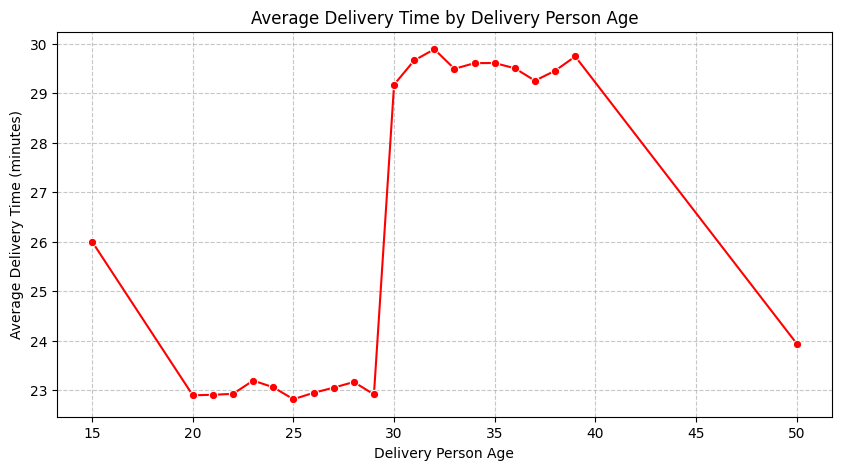

In [49]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Let's find the correct path for Zomato Dataset.csv
target_file = "Zomato Dataset.csv"
file_path = None

for root, dirs, files in os.walk("."):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        break

if file_path is None:
    # Fallback search globally in common places if not found in current directory tree
    for root, dirs, files in os.walk("/content"):
        if target_file in files:
            file_path = os.path.join(root, target_file)
            break

if file_path:
    print(f"Found dataset at: {file_path}")
    # Load and clean the dataset
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip().str.replace(" ", "_")

    time_column = "Time_taken_(min)"
    if time_column in df.columns:
        df[time_column] = pd.to_numeric(df[time_column], errors="coerce")
        df["Delivery_person_Age"] = pd.to_numeric(df["Delivery_person_Age"], errors="coerce")

        # Drop NaNs for a clean correlation check
        clean_df = df.dropna(subset=["Delivery_person_Age", time_column])

        # Calculate correlation
        correlation = clean_df['Delivery_person_Age'].corr(clean_df[time_column])
        print(f"Correlation between Delivery Person Age and Delivery Time: {correlation:.4f}")

        # Group by Age to see the average delivery time for each age
        age_grouped = clean_df.groupby('Delivery_person_Age')[time_column].mean().reset_index()

        # Plot the relationship
        plt.figure(figsize=(10, 5))
        sns.lineplot(x='Delivery_person_Age', y=time_column, data=age_grouped, marker='o', color='red')
        plt.title('Average Delivery Time by Delivery Person Age')
        plt.xlabel('Delivery Person Age')
        plt.ylabel('Average Delivery Time (minutes)')
        plt.grid(True, linestyle='--', alpha=0.7)
        plt.show()
    else:
        print(f"Target column '{time_column}' not found in dataset!")
else:
    print("Could not find 'Zomato Dataset.csv' in the workspace. Please make sure the file is uploaded or check the path.")